# TDCS: Start Hesitation + Walking ensemble

## tl;dr

Dropping Turn from the **new output and metric**, then specializing the ensemble
by target, improved pooled two-target development mAP from
**0.1872** to **0.1963**.
StartHesitation AP is **0.2087**;
Walking AP remains **0.1839**.

The output is a separate 0–1 confidence **score** for each target, not an
exclusive class prediction. These scores are **not calibrated probabilities**.
Hesitation ranking improved, but its probability loss worsened and its scores
substantially underestimate event prevalence. Reliability diagnostics below
keep that tradeoff visible.

Saved scores were independently checked on all **6,959,762 native rows**.
Existing three-class TDCS and reported DeFOG **0.817** results are preserved.
No Kaggle scoring or submission. Selection reuses development folds and does
not establish an independent generalization gain.

## Context & Methods

Two independent target-specific ensembles use the preserved dense
spectral/context HGB, original multiscale HGB, and neural blend. The neural
member averages patch-BiLSTM and engineered BiGRU scores equally. The Turn
specialist is not loaded. Only StartHesitation and Walking columns are used.

Three bounded blend definitions were saved before this experiment's scores
were calculated. The retained reference uses 25% neural, 25% multiscale HGB,
and 50% dense HGB for both targets. Candidates give hesitation 80% or 90%
dense weight, sharing the remainder equally between the other two members;
Walking retains the reference blend. The selected candidate is the best
of these three ensembles on the reused development folds.

This is **recombination of existing models**, not a claim to have trained a
new two-head neural network. Sensor classifiers were already independent
per target; the historical neural models were originally trained on all
three labels. Their unwanted Turn output is discarded, not retrained here.

### Key Assumptions

- Same 815 recordings, 61 subjects, and five frozen subject-disjoint folds;
  public-example subject `4dc2f8` remains excluded.
- Keep every native row, including Turn-only and no-FOG rows. For the two
  retained labels those periods are negative examples, not deleted records.
- Separate scores need not sum to one. Both can be low. Low scores do **not**
  mean that Turn or all FOG has been ruled out.
- Two-target mAP is the mean of pooled native-row AP for these two targets,
  **not comparable** to the prior three-target mAP of 0.3877.
- Mean fold mAP is not the pooled metric. Repeated development-fold reuse
  means candidate selection can be optimistic.
- Features use accelerometer data and recording timing, with centered
  windows and full-record normalization: offline, not causal real-time use.
- Weighted ensemble outputs are ranking scores. No clinical certainty or
  calibrated-probability claim is made.

[Probability calibration reference](https://scikit-learn.org/stable/modules/calibration.html):
calibration should be learned from predictions independent of the base
model's fitting data. We do not fit a calibrator on all OOF rows and then
report its training reliability as validation.

## Data

This is a **local completed-experiment / ensemble companion**, not a standalone
Kaggle training or competition-submission notebook. It loads preserved
project models and native-row OOF scores. Run top-to-bottom from this project.
To rebuild the two-target experiment and its independent validation:

```powershell
.\.venv\Scripts\python.exe -u scripts/tdcs_two_target_ensemble.py
.\.venv\Scripts\python.exe scripts/validate_tdcs_two_target.py
```

Source artifacts are the independently validated multiscale and dense-context
TDCS runs plus the saved patch-BiLSTM and BiGRU predictions under
`kaggle-output/fog-evidence-weighted/competition/neural/tdcsfog`.
Outputs live in a separate `results/tdcs_two_target/<fingerprint>` directory.

### Load the preserved run

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents, Path('D:/Dissertation')]
PROJECT_ROOT = next(p for p in candidates if (p / 'scripts/tdcs_two_target_ensemble.py').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
import tdcs_two_target_ensemble as experiment

decision = json.loads((PROJECT_ROOT / 'results/tdcs_two_target/latest_run.json').read_text())
run_dir = Path(decision['run_dir'])
selected_dir = Path(decision['selected_candidate_dir'])
configuration = json.loads((run_dir / 'configuration.json').read_text())
validation = json.loads((selected_dir / 'validation.json').read_text())
metrics = pd.read_csv(run_dir / 'candidate_metrics.csv')
fold_metrics = pd.read_csv(run_dir / 'candidate_fold_metrics.csv')
confidence = pd.read_csv(run_dir / 'confidence_metrics.csv')
bins = pd.read_csv(run_dir / 'reliability_bins.csv')
manifest = pd.read_csv(selected_dir / 'frozen_tdcs_manifest.csv', dtype={'recording_id': str, 'subject': str})
print('Preserved run:', run_dir)
print('Targets:', ', '.join(experiment.TARGETS))

Preserved run: D:\Dissertation\results\tdcs_two_target\0bc6253ac0686c819425
Targets: StartHesitation, Walking


### Verify the independent native-row receipt

In [2]:
assert validation['status'] == 'passed'
assert validation['native_rows'] == 6959762
assert validation['recordings'] == 815 and validation['subjects'] == 61
assert validation['subject_disjoint'] and validation['prediction_ids_exact_match']
assert validation['all_native_rows_retained'] and validation['old_three_class_registry_unchanged']
assert validation['targets'] == list(experiment.TARGETS)
assert validation['calibration_bin_counts_verified'] and not validation['confidence_is_calibrated']
selected = metrics.loc[metrics.method.eq(decision['selected_method'])].iloc[0]
for name in [*experiment.TARGETS, 'two_target_mAP']:
    assert abs(selected[name] - validation['independent_rank_based_AP'][name]) < 1e-10
display(pd.DataFrame([{'check': name, 'value': validation[name]} for name in
                     ['recordings', 'subjects', 'native_rows', 'subject_disjoint',
                      'all_native_rows_retained', 'turn_output_removed', 'confidence_is_calibrated']]))

,check,value
0,recordings,815
1,subjects,61
2,native_rows,6959762
3,subject_disjoint,True
4,all_native_rows_retained,True
5,turn_output_removed,True
6,confidence_is_calibrated,False


### Inspect the selected weights

In [3]:
weights = pd.DataFrame(decision['target_weights'], index=experiment.MEMBERS).T
display(weights.style.format('{:.0%}'))
print('Neural = equal patch-BiLSTM + engineered BiGRU; no Turn specialist.')
print('Existing neural weights were trained historically with three output heads.')

Neural = equal patch-BiLSTM + engineered BiGRU; no Turn specialist.
Existing neural weights were trained historically with three output heads.


,neural,multiscale_hgb,dense_context_hgb
StartHesitation,5%,5%,90%
Walking,25%,25%,50%


## Results

### Compare all candidates, not the three-class metric

,method,StartHesitation,Walking,two_target_mAP
2,hesitation_dense_90_walking_retained,0.2087,0.1839,0.1963
1,hesitation_dense_80_walking_retained,0.2004,0.1839,0.1922
0,current_model_two_target_reference,0.1905,0.1839,0.1872
3,dense_context_hgb_only_reference,0.2104,0.1596,0.1850


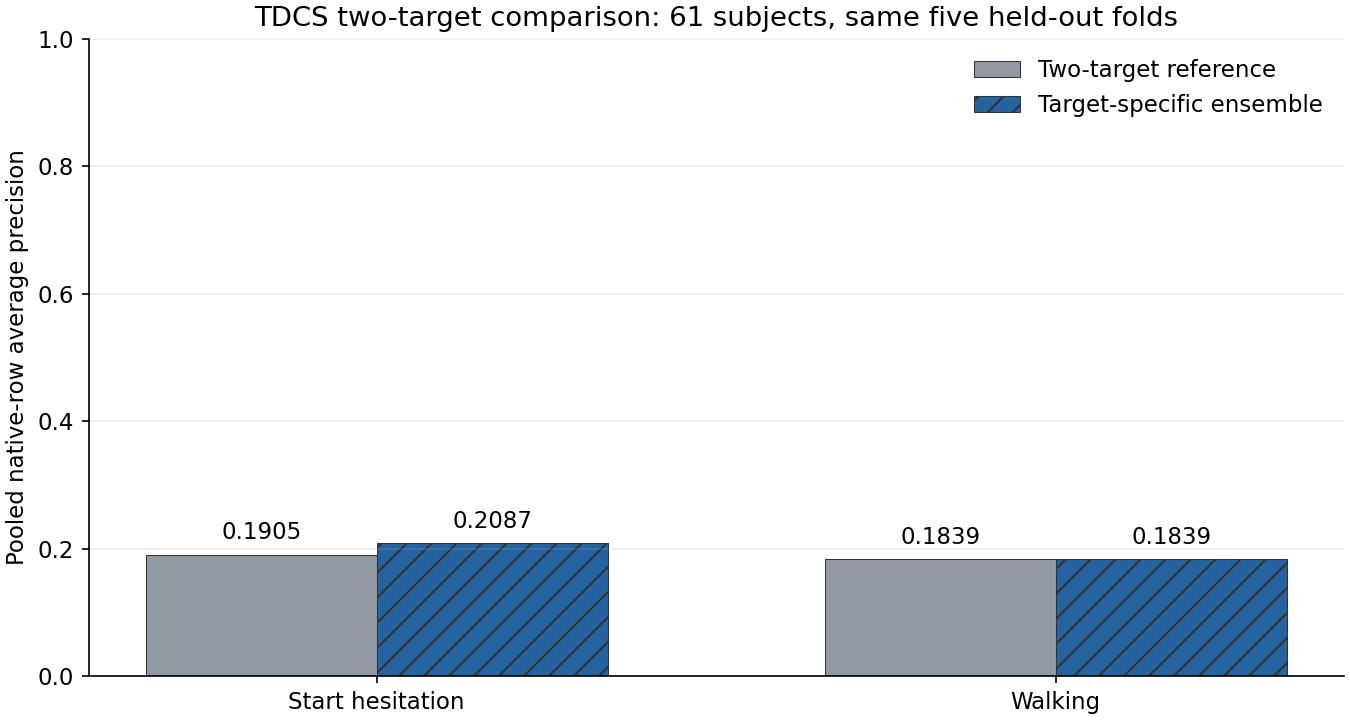

In [4]:
display(metrics.sort_values('two_target_mAP', ascending=False).style.format(
    {name: '{:.4f}' for name in [*experiment.TARGETS, 'two_target_mAP']}))
figures = experiment.make_figures(metrics, bins, decision['selected_method'], run_dir)
display(Image(filename=str(figures[0])))

Hesitation improves from 0.1905 to 0.2087 while Walking stays at 0.1839.
Dense-only hesitation ranks slightly better, but its Walking result is weaker;
the per-target ensemble protects Walking. This is development selection.

### Check confidence quality separately from AP

In [5]:
columns = ['method', 'target', 'prevalence', 'mean_confidence_score', 'brier_loss',
           'log_loss', 'ece_10_uniform_bins']
display(confidence[columns].style.format({name: '{:.4f}' for name in columns[2:]}))
print('Brier/log loss assess probability quality and discrimination; lower is better.')
print('ECE uses ten equal-width bins and can hide within-bin or rare-event errors.')

Brier/log loss assess probability quality and discrimination; lower is better.
ECE uses ten equal-width bins and can hide within-bin or rare-event errors.


,method,target,prevalence,mean_confidence_score,brier_loss,log_loss,ece_10_uniform_bins
0,current_model_two_target_reference,StartHesitation,0.0438,0.0130,0.0409,0.1655,0.0318
1,current_model_two_target_reference,Walking,0.0298,0.0268,0.0265,0.1013,0.0048
2,hesitation_dense_90_walking_retained,StartHesitation,0.0438,0.0050,0.0428,0.2068,0.0401
3,hesitation_dense_90_walking_retained,Walking,0.0298,0.0268,0.0265,0.1013,0.0048


The selected hesitation ensemble's mean score is **0.0050**, while event
prevalence is **0.0438**. Its Brier loss **0.0428** and log loss **0.2068**
are worse than the previous hesitation scores (0.0409 / 0.1655). This is
a ranking improvement, **not** a probability-quality improvement.
Walking is unchanged: Brier loss 0.0265, log loss 0.1013.

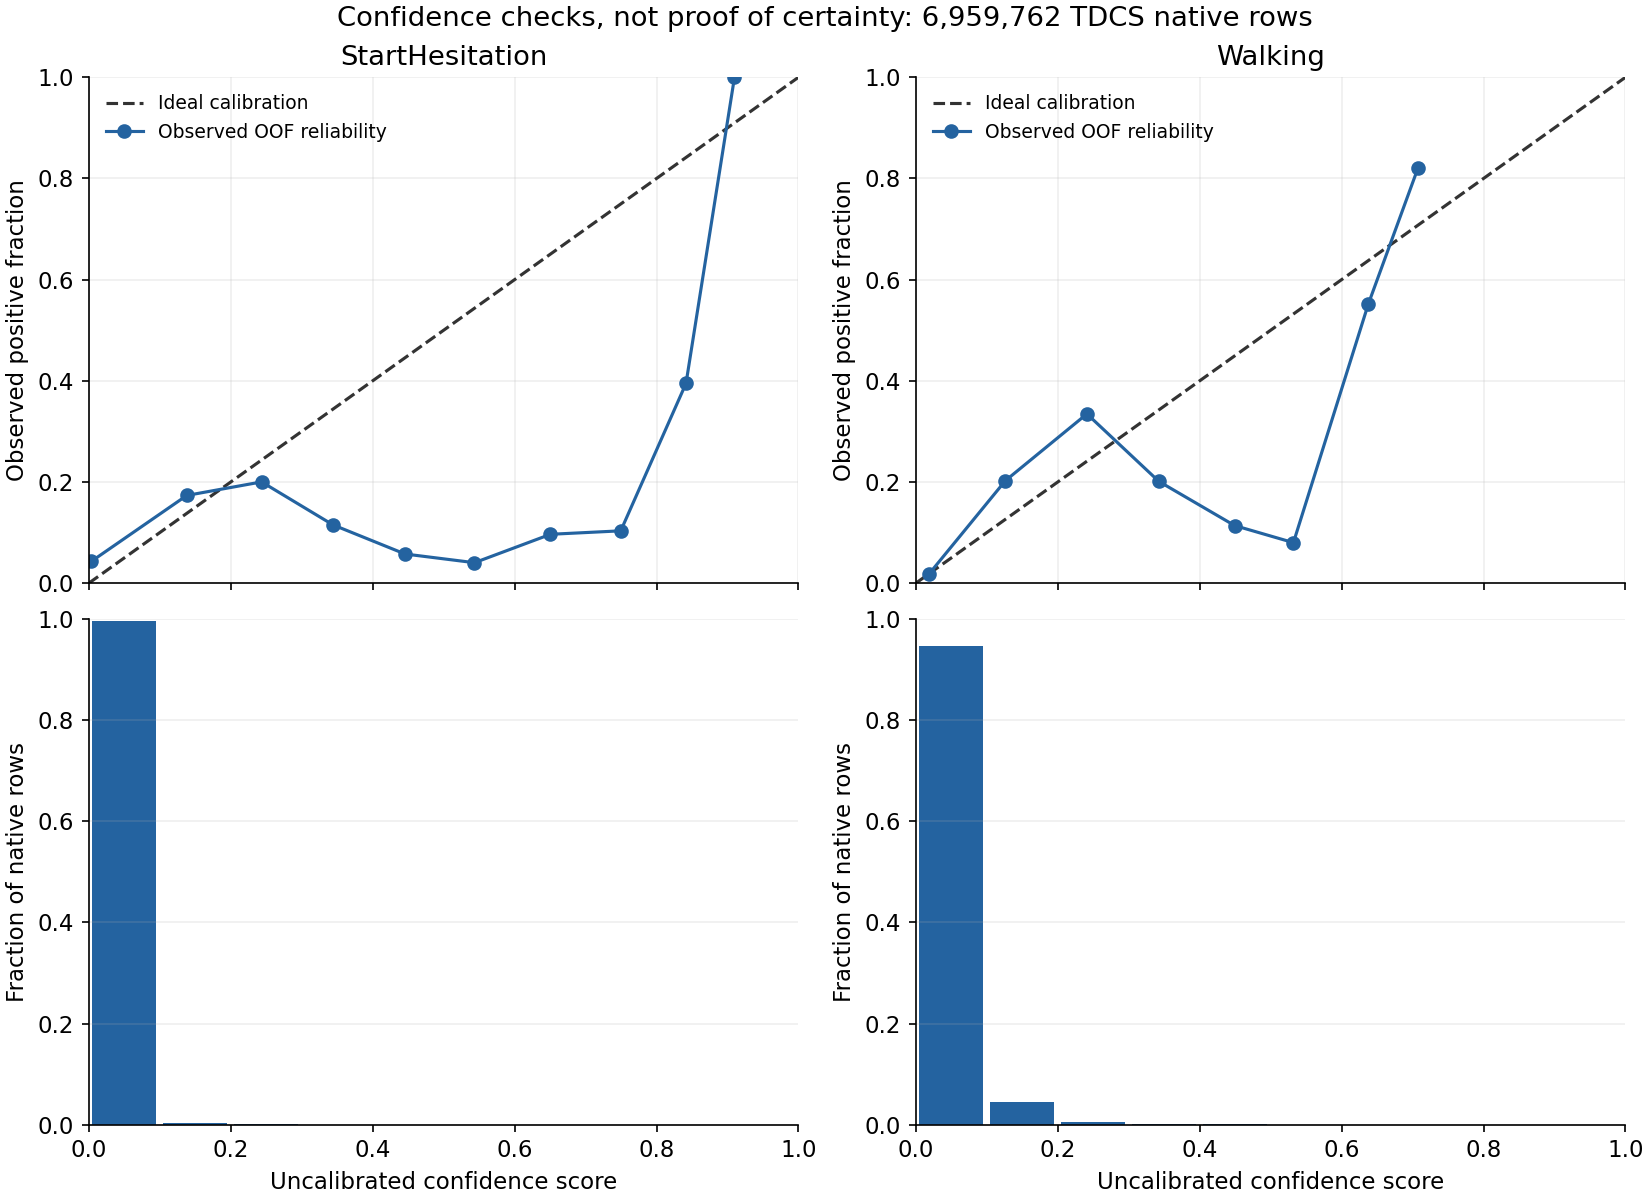

In [6]:
display(Image(filename=str(figures[1])))

Reliability shows native-row empirical rates, not a confidence interval.
Row counts are heavily correlated within recordings and subjects; high
native-row volume is not millions of independent observations. An apparent
match to the ideal line does not establish clinical calibration.

### Inspect fold variation

In [7]:
display(fold_metrics.loc[fold_metrics.method.eq(decision['selected_method'])].style.format(
    {name: '{:.4f}' for name in [*experiment.TARGETS, 'two_target_mAP']}))
print('StartHesitation is imbalanced between subject folds; improvement is not universal.')

StartHesitation is imbalanced between subject folds; improvement is not universal.


,method,fold,StartHesitation,Walking,two_target_mAP
10,hesitation_dense_90_walking_retained,0,0.4688,0.2079,0.3384
11,hesitation_dense_90_walking_retained,1,0.1084,0.2207,0.1645
12,hesitation_dense_90_walking_retained,2,0.1280,0.0543,0.0911
13,hesitation_dense_90_walking_retained,3,0.0983,0.0808,0.0896
14,hesitation_dense_90_walking_retained,4,0.0738,0.0609,0.0674


### Reproduce one recording from saved models, without loading Turn

In [8]:
row = manifest.iloc[0]
raw = pd.read_csv(row.path, usecols=list(experiment.base.AXES)).loc[:, list(experiment.base.AXES)].to_numpy()
sensor = Path(configuration['sensor_run'])
dense = Path(configuration['dense_run'])
# One held-out fold for a fair OOF replay; average all five for an unseen new recording.
members = experiment.predict_sensor_members(raw, sensor, dense, folds=(int(row.fold),))
neural_root = PROJECT_ROOT / 'kaggle-output/fog-evidence-weighted/competition/neural/tdcsfog'
neural_parts = []
for branch in ['patch_bilstm', 'engineered_bigru']:
    path = neural_root / branch / f'fold_{row.fold}/seed_42/oof/{row.recording_id}.npz'
    with np.load(path, allow_pickle=False) as payload:
        neural_parts.append(payload['prediction'][:, experiment.SOURCE_INDICES])
members['neural'] = 0.5 * neural_parts[0] + 0.5 * neural_parts[1]
scores = experiment.combine_members(members, decision['target_weights'])
with np.load(selected_dir / 'oof' / f'{row.recording_id}.npz', allow_pickle=False) as payload:
    np.testing.assert_allclose(scores, payload['prediction'], atol=2e-6, rtol=0)
output = pd.DataFrame({
    'Id': [f'{row.recording_id}_{i}' for i in range(len(scores))],
    'StartHesitation_confidence_score': scores[:, 0],
    'Walking_confidence_score': scores[:, 1],
})
display(output.head(8).style.format({name: '{:.5f}' for name in output.columns[1:]}))
print('Saved-model replay passed:', row.recording_id, len(scores), 'native rows.')

Saved-model replay passed: 009ee11563 9920 native rows.


C:\Users\Rahul\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Rahul\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Rahul\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Rahul\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

,Id,StartHesitation_confidence_score,Walking_confidence_score
0,009ee11563_0,0.00218,0.00087
1,009ee11563_1,0.00191,0.00080
2,009ee11563_2,0.00173,0.00077
3,009ee11563_3,0.00163,0.00076
4,009ee11563_4,0.00155,0.00075
5,009ee11563_5,0.00149,0.00074
6,009ee11563_6,0.00145,0.00073
7,009ee11563_7,0.00141,0.00072


For a **new unseen** recording, supply its SH/Walking neural scores in the
same native-row order, call `predict_sensor_members` with all five folds,
then call `combine_members` with the selected weights. This notebook does
not regenerate the historical neural networks; their predictions are required.
This two-column research output is not a competition-valid three-column submission.

## Takeaways

Keep the two-target ranking ensemble separately from the preserved three-class
model. Next, genuinely retrain a two-output neural specialist and reserve
subject-disjoint calibration data. Calibration must not use the same subjects
whose probability accuracy is being reported, and its base-model training
must also exclude the outer evaluation subjects.

Do not interpret an 80% raw confidence score as an 80% event probability.
Preserve difficult negative rows, all native-row alignment, and the same
subject folds; no leaderboard submission is needed for these experiments.

In [9]:
print(f"Two-target development mAP: {decision['two_target_reference_mAP']:.4f} -> {decision['two_target_mAP']:.4f}")
print('Confidence scores are uncalibrated, especially StartHesitation.')
print('Three-class TDCS and DeFOG 0.817 preserved. No competition scoring/submission.')

Two-target development mAP: 0.1872 -> 0.1963
Confidence scores are uncalibrated, especially StartHesitation.
Three-class TDCS and DeFOG 0.817 preserved. No competition scoring/submission.
